# Misconception #18: a small P value predicts a small replication P value

**If a first study has P < 0.05, how often will an independent replication also have P < 0.05?**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams.update({"figure.dpi": 130, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, ORANGE = "#236A9F", "#7A828C", "#BF650F"


## A simple model with an explicit sample size

Each study has **n independent observations** from a normal population with a fixed true mean shift $\delta$ and known population standard deviation $\sigma$:

$$X_i \sim N(\delta,\sigma^2), \qquad H_0:\delta=0.$$

For a two-sided z test,

$$\mathrm{SE}=\frac{\sigma}{\sqrt n}, \qquad Z=\frac{\bar X}{\mathrm{SE}}, \qquad P=2\Phi(-|Z|).$$

We simulate sample means directly from their exact distribution, $\bar X\sim N(\delta,\sigma^2/n)$, which is equivalent to generating all the raw normal observations and averaging them. The first study and replication are independent, with the same fixed effect and design.

The defaults preserve the original example: $\delta=0.08$, $\sigma=1$, and $n=25$. Thus $\delta/\mathrm{SE}=0.4$, giving **about 6.85% power** at $\alpha=0.05$. This is a low-power example despite a nonzero true effect. Change `N` to 400 or 1600 to see how the distribution changes as the studies become more informative. `N_PAIRS` is the number of simulated study pairs, separate from the sample size within each study.


In [2]:
# Study parameters: delta and sigma are in the same outcome units.
DELTA = 0.08       # True mean shift; set to 0 for the null case.
SIGMA = 1.0        # Known population standard deviation (positive).
N = 25             # Independent observations in EACH study (positive integer).
N_PAIRS = 200_000   # Number of independent first-study/replication pairs.
ALPHA = 0.05
SEED = 1819

se = SIGMA / np.sqrt(N)
mean_z = DELTA / se
rng = np.random.default_rng(SEED)
mean1 = rng.normal(loc=DELTA, scale=se, size=N_PAIRS)
mean2 = rng.normal(loc=DELTA, scale=se, size=N_PAIRS)
z1, z2 = mean1 / se, mean2 / se
p1 = 2 * norm.sf(np.abs(z1))
p2 = 2 * norm.sf(np.abs(z2))
first_significant = p1 < ALPHA
replication_significant = p2 < ALPHA

# Exact CDF of the two-sided P value when Z ~ Normal(mean_z, 1).
# At u = ALPHA, this is the study's power (or type-I error rate if DELTA = 0).
def p_value_cdf(u, mean_z):
    cutoff = norm.isf(np.asarray(u) / 2)
    return norm.sf(cutoff - mean_z) + norm.cdf(-cutoff - mean_z)

power = float(p_value_cdf(ALPHA, mean_z))
selected_replication_rate = (
    replication_significant[first_significant].mean()
    if first_significant.any() else np.nan
)
print(f"delta = {DELTA:g}, sigma = {SIGMA:g}, n = {N:,} observations per study")
print(f"SE = {se:g}; effect / SE = {mean_z:g}; effect / SD = {DELTA / SIGMA:g}")
print(f"Pairs simulated: {N_PAIRS:,}")
print(f"Theoretical power for either study: {power:.2%}")
print(f"First study significant: {first_significant.mean():.2%}")
print(f"Both significant: {(first_significant & replication_significant).mean():.2%} "
      f"(theory: power squared = {power**2:.2%})")
print(f"Replication significant given first significant: {selected_replication_rate:.2%} "
      f"(theory: power = {power:.2%})")


delta = 0.08, sigma = 1, n = 25 observations per study
SE = 0.2; effect / SE = 0.4; effect / SD = 0.08
Pairs simulated: 200,000
Theoretical power for either study: 6.85%
First study significant: 6.92%
Both significant: 0.48% (theory: power squared = 0.47%)
Replication significant given first significant: 6.98% (theory: power = 6.85%)


## What does the P-value distribution look like when the effect is nonzero?

Use **all replication studies** here, before selecting on the first result. The histogram shows their simulated P values; the theoretical step curve gives the exact average density within the same bins. The dashed gray line shows the uniform density expected under a true null. A nonzero effect shifts probability toward small P values, but with these low-power defaults the distribution is still close to uniform.

The right panel compares the simulated and theoretical cumulative distributions: at a value $u$, the curve's height is $\Pr(P\leq u)$. Its height at $\alpha=0.05$ is the study's power. The theoretical calculation uses the two normal tails beyond $q=\Phi^{-1}(1-u/2)$:

$$\Pr(P\leq u)=\Pr(Z\geq q)+\Pr(Z\leq -q), \qquad Z\sim N(\delta\sqrt n/\sigma,1).$$

When $\delta=0$, this reduces to $\Pr(P\leq u)=u$. Increase `N` while holding `DELTA` and `SIGMA` fixed to see more P values accumulate near zero.


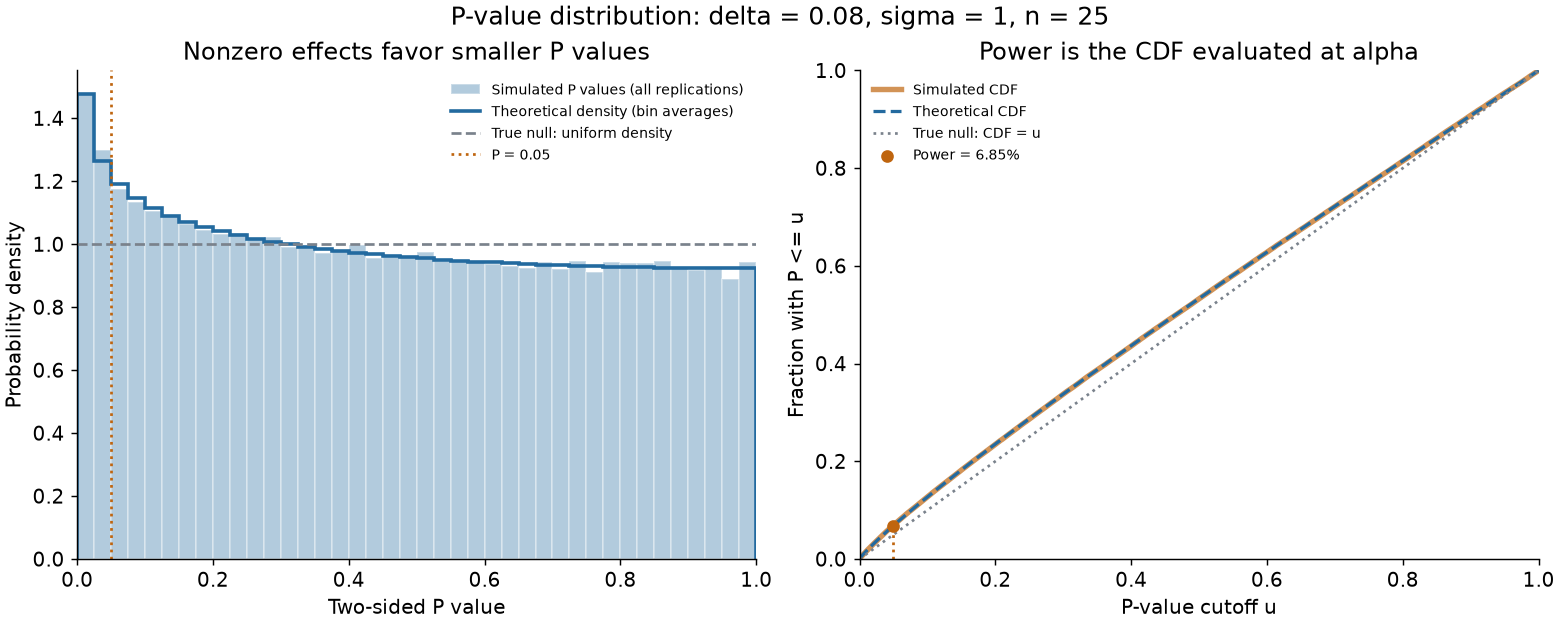

In [3]:
bins = np.linspace(0, 1, 41)
theoretical_density = np.diff(p_value_cdf(bins, mean_z)) / np.diff(bins)
p_grid = np.linspace(0, 1, 501)
theoretical_cdf = p_value_cdf(p_grid, mean_z)
simulated_cdf = np.searchsorted(np.sort(p2), p_grid, side="right") / N_PAIRS

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
fig.suptitle(f"P-value distribution: delta = {DELTA:g}, sigma = {SIGMA:g}, n = {N:,}", fontsize=14)

ax = axes[0]
ax.hist(p2, bins=bins, density=True, color=BLUE, alpha=0.35, edgecolor="white",
        label="Simulated P values (all replications)")
ax.stairs(theoretical_density, bins, color=BLUE, lw=2,
          label="Theoretical density (bin averages)")
ax.axhline(1, color=GRAY, ls="--", label="True null: uniform density")
ax.axvline(ALPHA, color=ORANGE, ls=":", label=f"P = {ALPHA:g}")
ax.set(xlim=(0, 1), xlabel="Two-sided P value", ylabel="Probability density",
       title="Nonzero effects favor smaller P values")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.plot(p_grid, simulated_cdf, color=ORANGE, lw=3, alpha=0.7, label="Simulated CDF")
ax.plot(p_grid, theoretical_cdf, color=BLUE, lw=1.8, ls="--", label="Theoretical CDF")
ax.plot([0, 1], [0, 1], color=GRAY, ls=":", label="True null: CDF = u")
ax.plot([ALPHA, ALPHA], [0, power], color=ORANGE, ls=":")
ax.scatter([ALPHA], [power], color=ORANGE, zorder=5, label=f"Power = {power:.2%}")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="P-value cutoff u", ylabel="Fraction with P <= u",
       title="Power is the CDF evaluated at alpha")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()


## Now select first studies with P < 0.05

The left panel compares first-study and replication P values among those pairs. The right panel shows the replication P values in the selected pairs. With a **fixed true effect and independent studies**, selecting the first result leaves the replication P distribution unchanged in theory; finite simulations give small differences. Compare this histogram with the distribution of all replications above.

The probability that **both** studies are significant is power squared. Given that the first study is already significant, the probability the replication is significant is power. At these defaults, those probabilities are about 0.47% and 6.85%, respectively.


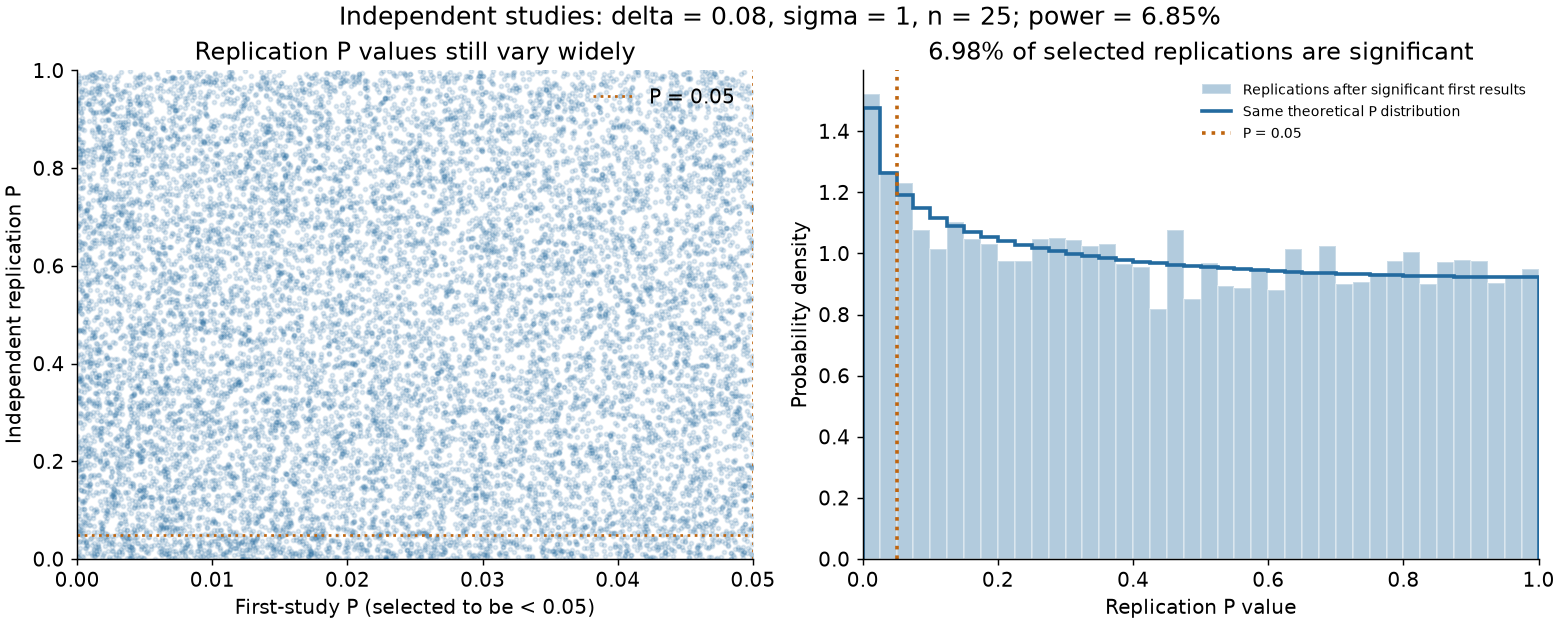

In [4]:
selected = first_significant
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
fig.suptitle(
    f"Independent studies: delta = {DELTA:g}, sigma = {SIGMA:g}, n = {N:,}; power = {power:.2%}",
    fontsize=14,
)

ax = axes[0]
ax.scatter(p1[selected], p2[selected], s=5, alpha=0.14, color=BLUE, rasterized=True)
ax.axvline(ALPHA, color=ORANGE, ls=":")
ax.axhline(ALPHA, color=ORANGE, ls=":", label=f"P = {ALPHA:g}")
ax.set(xlim=(0, ALPHA), ylim=(0, 1), xlabel=f"First-study P (selected to be < {ALPHA:g})",
       ylabel="Independent replication P", title="Replication P values still vary widely")
ax.legend(frameon=False)

ax = axes[1]
ax.hist(p2[selected], bins=bins, density=True, color=BLUE, alpha=0.35, edgecolor="white",
        label="Replications after significant first results")
ax.stairs(theoretical_density, bins, color=BLUE, lw=2, label="Same theoretical P distribution")
ax.axvline(ALPHA, color=ORANGE, ls=":", lw=2, label=f"P = {ALPHA:g}")
ax.set(xlim=(0, 1), xlabel="Replication P value", ylabel="Probability density",
       title=f"{selected_replication_rate:.2%} of selected replications are significant")
ax.legend(frameon=False, fontsize=8)
plt.show()


## What this demonstrates

The default is a real but very weak signal relative to its standard error: power is only about 6.85%. A significant first result can occur, yet most independent replications will be nonsignificant. Increasing the sample size makes smaller P values more common and increases power, while sampling variation remains.

The independence statements here condition on the same fixed true effect and study design. In an actual study the effect is unknown, and the first study can inform our beliefs about it. This simulation illustrates P-value variability; it does not calculate a replication probability from a particular observed P value.

Based on misconception 18 in Greenland et al. (2016), p. 343, *Statistical tests, P values, confidence intervals, and power: a guide to misinterpretations*. This is an illustrative normal-model simulation, not data from the paper.
